# 03 — Nihai Model, Kilitli Test Tahminleri ve Bağımsız Test

**Bölüm A (kilitleme):** Nihai konfigürasyon tüm development üzerinde 3 seed ile eğitilir; test tahminleri **etiket sütunu olmadan**
`results/test_predictions_locked.csv` dosyasına yazılır. Bu bölümde test etiketleri okunmaz.

➜ Bölüm A bittikten sonra kilitli dosya **ayrı bir commit** ile GitHub'a yüklenir.

**Bölüm B (değerlendirme):** Yalnızca kilitli commit doğrulandıktan sonra test etiketleri okunur ve metrikler hesaplanır.

## 0. Kurulum

In [1]:
# Google Colab'da çalıştırılıyorsa:
# !git clone https://github.com/mesutissever/ysa-midterm-mlp-nested-cv.git
# %cd ysa-midterm-mlp-nested-cv

In [2]:
import sys, os, json
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

from src.data import load_seeds, get_dev_test, get_test_features, TARGET
from src.final import (write_final_hyperparameters, train_final_models, write_locked_predictions,
                       check_lock_committed, LOCKED_PATH, THRESHOLD)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
FIG, RES = "figures", "results"
def savefig(name): plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
seeds = load_seeds()

# BÖLÜM A — Kilitleme (test etiketleri kullanılmaz)

## A1. Nihai konfigürasyon
Seçim, `02_nested_cv.ipynb` içinde tüm development iç CV'si ile önceden tanımlı kurala göre yapılmıştır.

In [3]:
dev_sel = json.load(open(f"{RES}/dev_selection.json", encoding="utf-8"))
final_hp = write_final_hyperparameters(dev_sel, seeds)
print(json.dumps(final_hp, ensure_ascii=False, indent=1))
if final_hp["src_or_configs_uncommitted"]:
    print("\nUYARI: src/ veya configs/ altında commit edilmemiş değişiklik var. Kod sürümü kaydı için önce commit edin.")

{
 "selected_code": "M2",
 "procedure": "manual_search",
 "config": {
  "code": "M2",
  "optimizer": "adam",
  "hidden": [
   32
  ],
  "activation": "relu",
  "lr": 0.001,
  "weight_decay": 0.0001,
  "batch_size": 64,
  "scaler": "standard",
  "dropout": 0.0,
  "clip": false,
  "scheduler": true
 },
 "selection_rule": "Tüm development inner CV (3 kat) mean AP en yüksek; eşitlikte n_params küçük, sonra kod sırası",
 "dev_inner_cv_mean_AP": 0.44077544285653764,
 "dev_inner_cv_sd_AP": 0.045598844576440145,
 "manual_best": "M2",
 "random_best": "R4",
 "threshold": 0.5,
 "threshold_note": "Varsayılan 0.50; eşik araması yapılmamıştır.",
 "primary_seed": 31046,
 "stability_seeds": [
  31046,
  31146,
  31246
 ],
 "early_stop_split_seed": 31044,
 "training_data": "Tüm development (3.295) -> %85 fit / %15 early-stop (stratified)",
 "versions": {
  "python": "3.13.1",
  "torch": "2.15.0+cpu",
  "sklearn": "1.9.1",
  "platform": "Windows-11-10.0.26200-SP0"
 },
 "code_commit": "8a81da2b76b84c6693

## A2. Nihai eğitim: tüm development, 3 seed (ana seed: ilk seed) + LogisticRegression
Her seed için development içinden %15 stratified early-stop alt kümesi ayrılır (seed 31044); ön işleme yalnızca %85 fit alt kümesinde öğrenilir.

In [4]:
df_dev, _ = get_dev_test()                       # test kısmı '_' — kullanılmıyor
config = final_hp["config"]
results, logreg, final_summary = train_final_models(df_dev, config, seeds)
final_summary

seed 31046: best_epoch=20 stopped=35 best_val_loss=0.2628 params=2017 t=20.4s 
seed 31146: best_epoch=18 stopped=33 best_val_loss=0.2605 params=2017 t=1.5s 
seed 31246: best_epoch=18 stopped=33 best_val_loss=0.2662 params=2017 t=1.6s 


,seed,primary,n_params,n_inputs,n_fit,n_es,best_epoch,stopped_epoch,early_stopped,best_val_loss,final_lr,train_time_s,failed,warnings
0,31046,True,2017,61,2800,495,20,35,True,0.262767,0.00025,20.380030,False,
1,31146,False,2017,61,2800,495,18,33,True,0.260491,0.00025,1.543983,False,
2,31246,False,2017,61,2800,495,18,33,True,0.266193,0.00025,1.565299,False,


### Şekil 4b — Nihai modelin (ana seed) eğitim ve early-stop doğrulama kaybı; öğrenme oranı

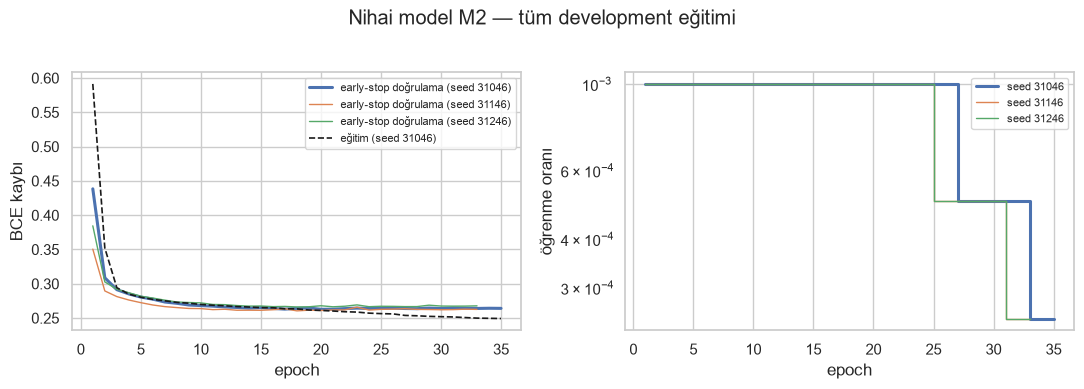

In [5]:
fh = pd.read_csv(f"{RES}/final_training_histories.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for s, g in fh.groupby("seed"):
    lw = 2.2 if s == final_hp["primary_seed"] else 1
    axes[0].plot(g.epoch, g.val_loss, lw=lw, label=f"early-stop doğrulama (seed {s})")
    axes[1].step(g.epoch, g.lr, where="post", lw=lw, label=f"seed {s}")
g = fh[fh.seed == final_hp["primary_seed"]]
axes[0].plot(g.epoch, g.train_loss, "k--", lw=1.2, label=f"eğitim (seed {final_hp['primary_seed']})")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("BCE kaybı"); axes[0].legend(fontsize=8)
axes[1].set_yscale("log"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("öğrenme oranı"); axes[1].legend(fontsize=8)
fig.suptitle(f"Nihai model {final_hp['selected_code']} — tüm development eğitimi", y=1.02)
plt.tight_layout(); savefig("final_training_curves"); plt.show()

## A3. Kilitli test tahminleri (etiketsiz)
`get_test_features()` test kümesinin yalnızca özelliklerini döndürür; etiket sütunu bu aşamada okunmaz.

In [6]:
X_test = get_test_features()
assert TARGET not in X_test.columns
locked, manifest = write_locked_predictions(results, logreg, X_test, seeds)
print(json.dumps(manifest, ensure_ascii=False, indent=1))
locked.head()

{
 "file": "results/test_predictions_locked.csv",
 "sha256": "0acd5903bfe0e4b90fa04838ac78b808e799f1c34158ef998ab22058f8b451d1",
 "n_rows": 824,
 "columns": [
  "orig_index",
  "prob_mlp_s31046",
  "pred_mlp_s31046",
  "prob_mlp_s31146",
  "pred_mlp_s31146",
  "prob_mlp_s31246",
  "pred_mlp_s31246",
  "prob_logreg",
  "pred_logreg"
 ],
 "primary_model": "mlp_s31046",
 "threshold": 0.5,
 "contains_labels": false,
 "code_commit": "8a81da2b76b84c66931fb8e6d960c00f3b834416",
 "src_or_configs_uncommitted": false,
 "created_utc": "2026-11-17T16:49:26+00:00"
}


,orig_index,prob_mlp_s31046,pred_mlp_s31046,prob_mlp_s31146,pred_mlp_s31146,prob_mlp_s31246,pred_mlp_s31246,prob_logreg,pred_logreg
0,9,0.025882,0,0.027843,0,0.029446,0,0.024742,0
1,12,0.029229,0,0.031987,0,0.033524,0,0.043351,0
2,20,0.069470,0,0.077367,0,0.064841,0,0.086711,0
3,24,0.034436,0,0.043397,0,0.029873,0,0.032752,0
4,32,0.403840,0,0.471397,0,0.444536,0,0.511158,1


In [7]:
# Tahmin dağılımı (etiketsiz betimsel bilgi)
locked.filter(like="prob_").describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
prob_mlp_s31046,824.0,0.1060,0.1506,0.0054,0.0343,0.0516,0.0862,0.8642
prob_mlp_s31146,824.0,0.1060,0.1464,0.0039,0.0359,0.0542,0.0872,0.8647
prob_mlp_s31246,824.0,0.1094,0.1507,0.0068,0.0365,0.0537,0.0931,0.8528
prob_logreg,824.0,0.1086,0.1524,0.0074,0.0364,0.0552,0.0934,0.9330


---
## ⛔ DUR — Bölüm B'ye geçmeden önce commit et

```
git add results/test_predictions_locked.csv results/test_lock_manifest.json results/final_hyperparameters.json results/final_training_summary.csv results/final_training_histories.csv models/ figures/final_training_curves.png 03_final_test.ipynb
git commit -m "Kilitli test tahminleri (etiketsiz) - metrikler oncesi"
git push
```

Bölüm B'nin ilk hücresi bu commit'i doğrulamadan test etiketlerini okumaz.
Bu commit'ten sonra modele, eşiğe veya ön işlemeye müdahale edilmez.

# BÖLÜM B — Bağımsız test değerlendirmesi

**Bölüm A'yı yeniden çalıştırma.** Kilit commit'i atıldığı için Bölüm A fonksiyonları hata verir (`assert_not_locked`).
Bu bölüm kendi içinde bağımsızdır: aşağıdaki B0 hücresinden başlayıp **"Execute Cell and Below"** ile çalıştırın.

Bu bölümde model yeniden eğitilmez; kilitli CSV'deki olasılıklar olduğu gibi kullanılır. Eşik 0.50 sabittir,
hiçbir seçim veya ayar yapılmaz.

## B0. Kurulum ve kilit doğrulaması

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

from src.data import load_seeds, TARGET
from src.final import THRESHOLD
from src.evaluate import (load_locked_with_labels, model_columns, test_metrics, bootstrap_ci,
                          seed_stability, error_analysis)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
FIG, RES = "figures", "results"
def savefig(name): plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
seeds = load_seeds()

df, lock = load_locked_with_labels()      # kilit commit'i doğrulanmadan etiketler okunmaz
print(json.dumps(lock, ensure_ascii=False, indent=1))
print(f"\nTest: n={len(df)}, pozitif={int(df[TARGET].sum())} ({df[TARGET].mean():.4f})")
MODELS = model_columns(seeds)
MLP = list(MODELS)[0]

{
 "lock_commit": "cb19a1ca90d1f88e091a5e6e95a30356ce25c74b",
 "lock_commit_date": "2026-11-18 10:57:00 +0300",
 "lock_commit_message": "Nihai egitim ve kilitli tahmin kodu",
 "sha256": "0acd5903bfe0e4b90fa04838ac78b808e799f1c34158ef998ab22058f8b451d1"
}

Test: n=824, pozitif=90 (0.1092)


## B1. Tablo 8 — Bağımsız test metrikleri (eşik 0.50)
Dummy, development pozitif oranını sabit olasılık olarak verir (test'ten bir şey öğrenmez).

In [2]:
tm = test_metrics(df, seeds)
tm.set_index("model").round(4)

,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,TP,FP,TN,FN
model,,,,,,,,,,,,
"MLP (M2, seed 31046)",0.4064,0.7437,0.8968,0.5714,0.2222,0.9796,0.3200,0.6009,20,15,719,70
LogisticRegression,0.3905,0.7368,0.8981,0.5833,0.2333,0.9796,0.3333,0.6064,21,15,719,69
Dummy (prior),0.1092,0.5000,0.8908,0.0000,0.0000,1.0000,0.0000,0.5000,0,0,734,90


## B2. Bootstrap %95 güven aralıkları (1000 yeniden örnekleme, seed 31047)
Yüzdelik yöntemi; tek sınıf içeren yeniden örneklemler atlanır (`n_skipped`). Ayrıca aynı yeniden örneklemler
üzerinde **eşleştirilmiş fark** (MLP − LogReg) hesaplanır.

In [3]:
ci, diff = bootstrap_ci(df, seeds, n_boot=1000)
tab = ci.assign(value=[f"{p:.3f} [{l:.3f}, {h:.3f}]" for p, l, h in zip(ci.point, ci.ci_low, ci.ci_high)])
display(tab.pivot(index="model", columns="metric", values="value").loc[list(MODELS)])
print("Geçerli yeniden örnekleme:", ci.n_valid.iloc[0], "| atlanan:", ci.n_skipped.iloc[0])

metric,AP,F1,ROC_AUC
model,,,
"MLP (M2, seed 31046)","0.406 [0.313, 0.519]","0.320 [0.215, 0.431]","0.744 [0.682, 0.807]"
LogisticRegression,"0.390 [0.300, 0.509]","0.333 [0.222, 0.439]","0.737 [0.675, 0.802]"
Dummy (prior),"0.109 [0.089, 0.131]","0.000 [0.000, 0.000]","0.500 [0.500, 0.500]"


Geçerli yeniden örnekleme: 1000 | atlanan: 0


In [4]:
diff.round(4)

,comparison,metric,diff,ci_low,ci_high,p_boot_le0,ci_contains_0,n_valid
0,"MLP (M2, seed 31046) - LogisticRegression",AP,0.0159,-0.0139,0.0406,0.189,True,1000
1,"MLP (M2, seed 31046) - LogisticRegression",ROC_AUC,0.0069,-0.0088,0.0222,0.182,True,1000
2,"MLP (M2, seed 31046) - LogisticRegression",F1,-0.0133,-0.0624,0.0307,0.739,True,1000


## B3. Tablo 9 — Seed kararlılığı (nihai MLP, 3 seed)
Ana seed önceden belirlenmiştir; bu tablo yalnızca seed'e bağlı değişkenliği gösterir, seçim için kullanılmaz.

In [5]:
per_seed, stab = seed_stability(df, seeds)
display(per_seed.set_index("seed").round(4))
stab.set_index("metric")[["mean_sd", "min", "max"]].round(4)

,primary,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,TP,FP,TN,FN
seed,,,,,,,,,,,,,
31046,True,0.4064,0.7437,0.8968,0.5714,0.2222,0.9796,0.3200,0.6009,20,15,719,70
31146,False,0.4050,0.7470,0.8968,0.5758,0.2111,0.9809,0.3089,0.5960,19,14,720,71
31246,False,0.3961,0.7466,0.8956,0.5588,0.2111,0.9796,0.3065,0.5953,19,15,719,71


,mean_sd,min,max
metric,,,
AP,0.403 ± 0.006,0.3961,0.4064
ROC_AUC,0.746 ± 0.002,0.7437,0.7470
Accuracy,0.896 ± 0.001,0.8956,0.8968
Precision,0.569 ± 0.009,0.5588,0.5758
Sensitivity,0.215 ± 0.006,0.2111,0.2222
Specificity,0.980 ± 0.001,0.9796,0.9809
F1,0.312 ± 0.007,0.3065,0.3200
Balanced_Accuracy,0.597 ± 0.003,0.5953,0.6009


### Şekil 6 — Karışıklık matrisleri (eşik 0.50)

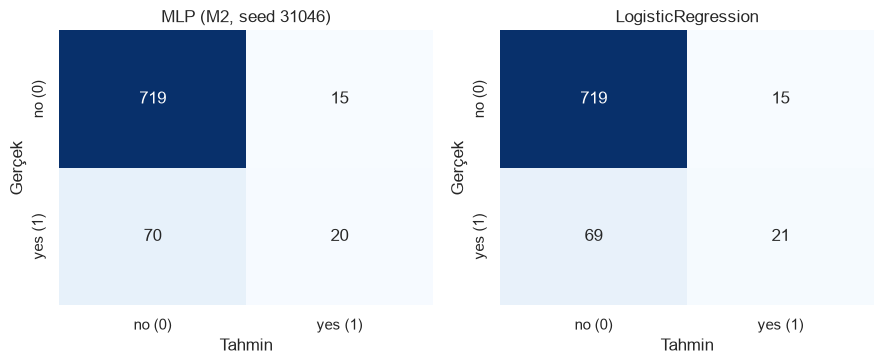

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, [MLP, "LogisticRegression"]):
    pred = (df[MODELS[name]] >= THRESHOLD).astype(int)
    cm = confusion_matrix(df[TARGET], pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no (0)", "yes (1)"], yticklabels=["no (0)", "yes (1)"])
    ax.set_xlabel("Tahmin"); ax.set_ylabel("Gerçek"); ax.set_title(name)
plt.tight_layout(); savefig("test_confusion"); plt.show()

### Şekil 7 — ROC ve Precision–Recall eğrileri (bağımsız test)

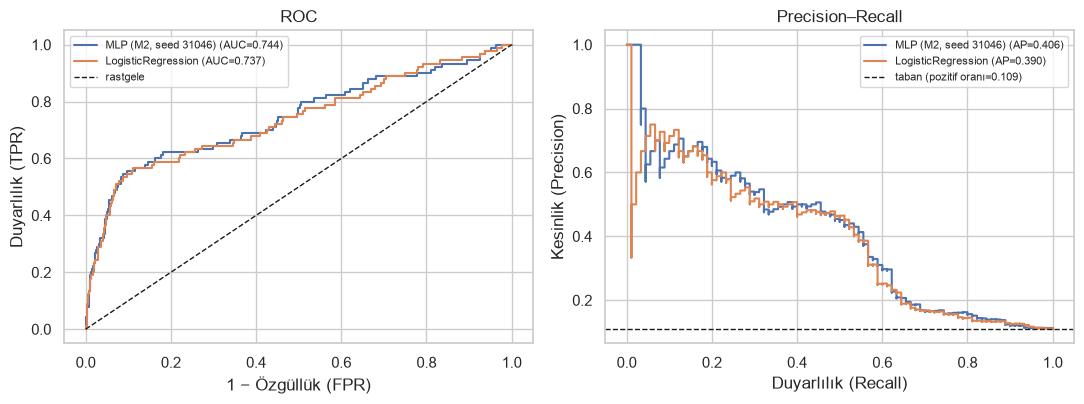

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
pos_rate = df[TARGET].mean()
for name in [MLP, "LogisticRegression"]:
    p = df[MODELS[name]]
    fpr, tpr, _ = roc_curve(df[TARGET], p)
    prec, rec, _ = precision_recall_curve(df[TARGET], p)
    row = tm.set_index("model").loc[name]
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={row.ROC_AUC:.3f})")
    axes[1].step(rec, prec, where="post", label=f"{name} (AP={row.AP:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="rastgele")
axes[0].set_xlabel("1 − Özgüllük (FPR)"); axes[0].set_ylabel("Duyarlılık (TPR)"); axes[0].set_title("ROC")
axes[1].axhline(pos_rate, color="k", ls="--", lw=1, label=f"taban (pozitif oranı={pos_rate:.3f})")
axes[1].set_xlabel("Duyarlılık (Recall)"); axes[1].set_ylabel("Kesinlik (Precision)"); axes[1].set_title("Precision–Recall")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); savefig("test_roc_pr"); plt.show()

## B4. Hata analizi (nihai MLP, ana seed)
En emin yanlış pozitifler (en yüksek olasılıklı FP) ve en emin yanlış negatifler (en düşük olasılıklı FN);
gerçek pozitifler içinde kategori bazında kaçırılma (FN) oranı; betimsel kalibrasyon.
Eşik 0.50'nin uygunluğu yalnızca tartışılır; test üzerinde eşik araması yapılmaz.

In [8]:
ea = error_analysis(df, MODELS[MLP])
print(ea["counts"].to_string())
print(f"\nOrtalama tahmin olasılığı: {ea['mean_prob']:.4f} | gözlenen pozitif oranı: {ea['pos_rate']:.4f}")
ea["errors"].round(3)

outcome
TP     20
FP     15
TN    719
FN     70

Ortalama tahmin olasılığı: 0.1060 | gözlenen pozitif oranı: 0.1092


,orig_index,y,prob,pred,outcome,age,job,contact,month,campaign,pdays,previous,poutcome,emp.var.rate,euribor3m,nr.employed
0,2792,0,0.804,1,FP,62,technician,cellular,jul,1,16,1,success,-1.7,0.827,4991.6
1,772,0,0.771,1,FP,35,blue-collar,cellular,dec,1,4,3,success,-3.0,0.707,5023.5
2,3049,0,0.757,1,FP,69,retired,cellular,sep,3,6,1,success,-1.1,0.879,4963.6
3,3547,0,0.742,1,FP,55,retired,cellular,jun,3,3,1,success,-2.9,1.268,5076.2
4,3216,0,0.733,1,FP,47,management,cellular,aug,3,3,2,success,-1.7,0.904,4991.6
5,3662,0,0.692,1,FP,46,admin.,cellular,aug,2,9,4,failure,-1.7,0.904,4991.6
6,3617,0,0.691,1,FP,55,admin.,telephone,oct,2,10,3,success,-1.1,0.977,4963.6
7,3402,0,0.669,1,FP,24,student,cellular,sep,1,17,4,failure,-1.1,0.886,4963.6
8,3717,0,0.632,1,FP,63,retired,cellular,dec,4,999,0,nonexistent,-3.0,0.706,5023.5
9,2041,0,0.630,1,FP,28,unemployed,cellular,oct,2,4,1,success,-3.4,0.752,5017.5


In [9]:
display(ea["fn_by_category"].sort_values(["feature", "n_pos"], ascending=[True, False]).round(3))
ea["calibration"].round(4)

,feature,level,n_pos,n_FN,FN_rate
3,contact,cellular,74,55,0.743
4,contact,telephone,16,15,0.938
8,month,jun,20,19,0.950
10,month,may,20,17,0.850
6,month,aug,14,8,0.571
11,month,nov,12,8,0.667
13,month,sep,7,3,0.429
5,month,apr,6,6,1.000
7,month,jul,6,6,1.000
12,month,oct,3,3,1.000


,prob,n,mean_prob,observed_rate
0,"(0.00436, 0.0314]",165,0.0241,0.0545
1,"(0.0314, 0.0449]",165,0.0379,0.0424
2,"(0.0449, 0.0593]",164,0.0520,0.0793
3,"(0.0593, 0.111]",165,0.0771,0.0485
4,"(0.111, 0.864]",165,0.3388,0.3212


---
## Bitti — commit
```
git add src/evaluate.py src/final.py 03_final_test.ipynb results/test_metrics.csv results/test_bootstrap_ci.csv results/test_bootstrap_diff.csv results/seed_stability_results.csv results/seed_stability_summary.csv results/test_error_analysis.csv results/test_fn_by_category.csv results/test_calibration_bins.csv figures/test_confusion.png figures/test_roc_pr.png
git commit -m "Bagimsiz test degerlendirmesi: metrikler, bootstrap GA, seed kararliligi, hata analizi"
git push
```